In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
def blue_score(image: np.ndarray) -> np.ndarray:
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV).astype(np.float32)

    h = hsv[..., 0]
    s = hsv[..., 1] / 255.0
    v = hsv[..., 2] / 255.0

    target_hue = 110.0
    hue_sigma = 10.0

    dh = np.abs(h - target_hue)
    dh = np.minimum(dh, 180.0 - dh)

    hue_score = np.exp(-0.5 * (dh / hue_sigma) ** 2)
    value_score = np.clip((v - 0.1) / 0.2, 0.0, 1.0)

    return hue_score * s * value_score

In [3]:
def find_tl_inner_corner(
    mask: np.ndarray,
    n: int,
) -> np.ndarray:
    """Find the TL inner corner using an empty n×n square.

    A valid candidate (row, col) has:
    - no marker pixels inside mask[row:row+n, col:col+n]
    - >=1 marker pixel immediately above that square
    - >=1 marker pixel immediately left of that square

    Returns [x, y].
    """
    mask = np.asarray(mask, dtype=bool)
    h, w = mask.shape

    if n < 1:
        raise ValueError("n must be >= 1")
    if n >= min(h, w):
        raise ValueError("n is too large for the mask")

    m = mask.astype(np.int32)

    # Integral image with a zero-padded top/left border.
    integral = np.pad(
        m.cumsum(axis=0).cumsum(axis=1),
        ((1, 0), (1, 0)),
    )

    # Candidate square top-left coordinates:
    #
    # row = 1 ... h-n
    # col = 1 ... w-n
    #
    # Starting at 1 leaves room for the marker immediately above/left.
    r0 = np.arange(1, h - n + 1)
    c0 = np.arange(1, w - n + 1)

    # Number of marker pixels inside every n×n candidate square.
    square_sum = (
        integral[r0[:, None] + n, c0[None, :] + n]
        - integral[r0[:, None],     c0[None, :] + n]
        - integral[r0[:, None] + n, c0[None, :]]
        + integral[r0[:, None],     c0[None, :]]
    )

    empty = square_sum == 0

    # Marker pixels immediately above each square.
    row_cumsum = np.pad(
        m.cumsum(axis=1),
        ((0, 0), (1, 0)),
    )

    top_sum = (
        row_cumsum[r0[:, None] - 1, c0[None, :] + n]
        - row_cumsum[r0[:, None] - 1, c0[None, :]]
    )

    touches_top = top_sum > 0

    # Marker pixels immediately left of each square.
    col_cumsum = np.pad(
        m.cumsum(axis=0),
        ((1, 0), (0, 0)),
    )

    left_sum = (
        col_cumsum[r0[:, None] + n, c0[None, :] - 1]
        - col_cumsum[r0[:, None],     c0[None, :] - 1]
    )

    touches_left = left_sum > 0

    valid = empty & touches_top & touches_left

    rows, cols = np.nonzero(valid)

    if rows.size == 0:
        raise ValueError("Could not find a valid TL inner corner.")

    # Convert indices within `valid` back to image coordinates.
    rows = r0[rows]
    cols = c0[cols]

    i = np.argmin(rows + cols)

    row = rows[i]
    col = cols[i]

    return np.array([col, row])

In [4]:
def find_inner_corner(mask, n, corner):
    h, w = mask.shape
    match corner:
        case "tl":
            adjusted_mask = mask
            inverse_adjust = lambda arr: arr
        case "tr":
            adjusted_mask = np.fliplr(mask)
            inverse_adjust = lambda arr: np.array([
                w - 1 - arr[0],
                arr[1],
            ])
        case "bl":
            adjusted_mask = np.flipud(mask)
            inverse_adjust = lambda arr: np.array([
                arr[0],
                h - 1 - arr[1],
            ])
        case "br":
            adjusted_mask = np.flip(mask, axis=(0, 1))
            inverse_adjust = lambda arr: np.array([
                w - 1 - arr[0],
                h - 1 - arr[1],
            ])
        case _:
            raise ValueError(f"Unknown corner: {corner!r}")
        
    tl = find_tl_inner_corner(adjusted_mask, n)
    return inverse_adjust(tl)

In [5]:
def warp_quad_to_square(
    image: np.ndarray,
    tl,
    tr,
    bl,
    br,
    size: int,
) -> np.ndarray:
    src = np.array((tl, tr, bl, br), dtype=np.float32)
    dst = np.array(
        [
            [0,        0],
            [size - 1, 0],
            [0,        size - 1],
            [size - 1, size - 1],
        ],
        dtype=np.float32,
    )

    transform = cv2.getPerspectiveTransform(src, dst)

    return cv2.warpPerspective(
        image,
        transform,
        (size, size),
    )

In [6]:
def draw_square(image, x, y, n):
    image_copy = image.copy()
    image_copy[y-n:y+n, x-n:x+n] = 0
    return image_copy

In [7]:
image = cv2.imread('1000015921.jpg')
h, w = image.shape[:2]

blue = blue_score(image)
mask = (blue > 0.4).astype(np.uint8) * 255

In [8]:
tl = find_inner_corner(mask, 100, "tl")
tr = find_inner_corner(mask, 100, "tr")
bl = find_inner_corner(mask, 100, "bl")
br = find_inner_corner(mask, 100, "br")

In [9]:
new_image = draw_square(image, *tl, 10)
new_image = draw_square(new_image, *tr, 10)
new_image = draw_square(new_image, *bl, 10)
new_image = draw_square(new_image, *br, 10)

In [10]:
warped = warp_quad_to_square(image, tl, tr, bl, br, 2160)

In [11]:
cv2.imwrite('warp.jpg', warped)

True

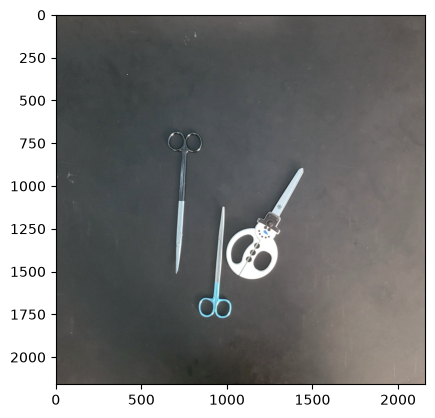

In [12]:
plt.imshow(warped)

In [13]:
tr

array([2849,  233])

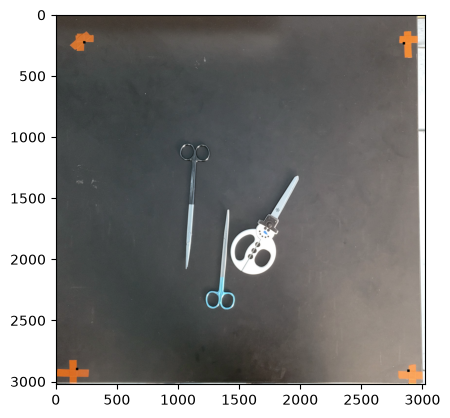

In [14]:
plt.imshow(new_image)